## 1. Parâmetros e bibliotecas

In [1]:
import math, heapq, time
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Parâmetros do modelo (Seção III)
V_NAVIO    = 18.5   # km/h - velocidade própria (tempo) / velocidade sobre o fundo (combustível)
V_MAX      = 25.0   # km/h - velocidade máxima da heurística de tempo (Eq. 9)
V_CORR_MAX = 0.8    # m/s  - limite superior adotado para a corrente (Seção III-H)
R_TERRA    = 6371.0 # km   - raio médio da Terra (Eq. 6)
DIRECOES = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]

# Fator da heurística de cada critério (por km de distância de Haversine ao destino)
C_MIN_KM = (V_NAVIO - 3.6 * V_CORR_MAX) ** 3 / V_NAVIO ** 4   
H_FATOR = {"weight": 1 / V_MAX, "comb": C_MIN_KM}               

## 2. Aquisição dos dados (NetCDF → planilha)

In [2]:
# Aquisição: NetCDF do Copernicus -> tabela -> planilha (Seção III-C/III-D)
import xarray as xr
ds = xr.open_dataset("cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m_1787250597644.nc")
print(ds)
ds.to_dataframe().to_excel("dados_marinhos.xlsx")

<xarray.Dataset> Size: 57kB
Dimensions:    (time: 3, depth: 1, latitude: 49, longitude: 48)
Coordinates:
  * time       (time) datetime64[ns] 24B 2026-08-18 2026-08-19 2026-08-20
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 196B -26.0 -25.92 -25.83 ... -22.08 -22.0
  * longitude  (longitude) float32 192B -47.0 -46.92 -46.83 ... -43.17 -43.08
Data variables:
    uo         (time, depth, latitude, longitude) float32 28kB ...
    vo         (time, depth, latitude, longitude) float32 28kB ...
Attributes:
    Conventions:       CF-1.11
    title:             daily mean fields from Global Ocean Physics Analysis a...
    institution:       Mercator Ocean International
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MOI GLO12
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           https://marine.copernicus.eu/contact
    references:        http://marine.copernicus.eu
    subset:

## 3. Pré-processamento e máscara de terra

In [3]:
# Pré-processamento (Seção III-D)
df = pd.read_excel("dados_marinhos.xlsx")
df[["time", "depth", "latitude"]] = df[["time", "depth", "latitude"]].ffill() 
df["magnitude"]   = np.hypot(df["uo"], df["vo"])      
df["direcao_rad"] = np.arctan2(df["vo"], df["uo"])
df["is_land"]     = df["uo"].isna()                    

lats = np.sort(df["latitude"].round(4).unique())
lons = np.sort(df["longitude"].round(4).unique())
instantes = sorted(df["time"].unique())

def matrizes(t):
    """Matrizes u_o, v_o e is_land (linha = latitude, coluna = longitude) para o instante t."""
    d = df[df["time"] == t]
    r = np.searchsorted(lats, d["latitude"].round(4).values)
    c = np.searchsorted(lons, d["longitude"].round(4).values)
    u = np.full((len(lats), len(lons)), np.nan); v = u.copy()
    u[r, c], v[r, c] = d["uo"].values, d["vo"].values
    return u, v, np.isnan(u) | np.isnan(v)

print(df.head(3).to_string())
print(f"\nGrade: {len(lats)} x {len(lons)} células | instantes: {[str(t)[:10] for t in instantes]}")

        time     depth  latitude  longitude        uo        vo  magnitude  direcao_rad  is_land
0 2026-08-18  0.494025     -26.0 -46.999992  0.009548 -0.188649   0.188891    -1.520225    False
1 2026-08-18  0.494025     -26.0 -46.916660  0.006938 -0.217154   0.217264    -1.538857    False
2 2026-08-18  0.494025     -26.0 -46.833324 -0.004664 -0.234313   0.234360    -1.590698    False

Grade: 49 x 48 células | instantes: ['2026-08-18', '2026-08-19', '2026-08-20']


## 4. Modelo: custos de tempo e de combustível, grafo, heurísticas e busca

In [4]:
# Modelo: distância, custos da aresta (Eq. 4-6 e 7-8), grafo (Eq. 3), heurísticas (Eq. 9 e 10) e buscas
def haversine(a, b):
    la1, lo1 = np.radians(a); la2, lo2 = np.radians(b)
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * R_TERRA * np.arcsin(np.sqrt(h))

def custos_aresta(cu, cv, uo, vo):
  
    dlat, dlon = cv[0] - cu[0], cv[1] - cu[1]
    norma = math.hypot(dlat, dlon)
    if norma == 0:
        return math.inf, math.inf
    proj = 3.6 * (vo * dlat + uo * dlon) / norma     
    d = haversine(cu, cv)
    v_ef, v_agua = V_NAVIO + proj, V_NAVIO - proj
    tempo = math.inf if v_ef <= 0.1 else d / v_ef
    comb = math.inf if v_agua <= 0.1 else (d / V_NAVIO) * (v_agua / V_NAVIO) ** 3
    return tempo, comb

def construir_grafo(lats, lons, u, v, is_land):
    G = nx.DiGraph()
    for r, c in zip(*np.where(~is_land)):
        G.add_node((r, c), pos=(lats[r], lons[c]))
    for (r, c) in list(G.nodes):
        for dr, dc in DIRECOES:
            n = (r + dr, c + dc)
            if n in G:
                if dr and dc and (is_land[r, c + dc] or is_land[r + dr, c]):
                    continue                      # diagonal não corta terra
                w, cb = custos_aresta(G.nodes[(r, c)]["pos"], G.nodes[n]["pos"],
                                      np.nan_to_num(u[r, c]), np.nan_to_num(v[r, c]))
                if w < math.inf and cb < math.inf:
                    G.add_edge((r, c), n, weight=w, comb=cb)
    return G

def busca(G, s, t, criterio="weight", usar_heuristica=True):
    
    pos = lambda n: G.nodes[n]["pos"]
    k = H_FATOR[criterio]
    h = (lambda n: haversine(pos(n), pos(t)) * k) if usar_heuristica else (lambda n: 0.0)
    g, pai, fechados, fila, cont = {s: 0.0}, {}, set(), [(h(s), 0, s)], 0
    while fila:
        _, _, n = heapq.heappop(fila)
        if n in fechados:
            continue
        fechados.add(n)
        if n == t:
            break
        for m, d in G[n].items():
            ng = g[n] + d[criterio]
            if ng < g.get(m, math.inf):
                g[m], pai[m] = ng, n
                cont += 1
                heapq.heappush(fila, (ng + h(m), cont, m))
    rota = [t]
    while rota[-1] != s:
        rota.append(pai[rota[-1]])
    return rota[::-1], g[t], len(fechados), len(g)

def custo_rota(G, rota, atributo):
    return sum(G[a][b][atributo] for a, b in zip(rota[:-1], rota[1:]))

def rota_direta(G, s, t):
    """Rota em linha reta: células amostradas sobre o segmento s-t, avaliada no MESMO grafo.
    Retorna células e arestas inválidas (terra / sem aresta)."""
    n = max(abs(t[0] - s[0]), abs(t[1] - s[1]))
    cel = []
    for k in range(n + 1):
        c = (int(round(s[0] + (t[0] - s[0]) * k / n)), int(round(s[1] + (t[1] - s[1]) * k / n)))
        if not cel or cel[-1] != c:
            cel.append(c)
    return cel, [p for p in zip(cel[:-1], cel[1:]) if not G.has_edge(*p)]

def comprimento_km(G, rota):
    return sum(haversine(G.nodes[a]["pos"], G.nodes[b]["pos"]) for a, b in zip(rota[:-1], rota[1:]))

def agua_mais_proxima(is_land, lat, lon):
    r0, c0 = np.abs(lats - lat).argmin(), np.abs(lons - lon).argmin()
    rr, cc = np.where(~is_land)
    i = ((rr - r0) ** 2 + (cc - c0) ** 2).argmin()
    return (int(rr[i]), int(cc[i]))

## 5. Verificação do grafo em grade de teste (Fig. 3)

Grade de teste: 1552 nós | 11856 arestas


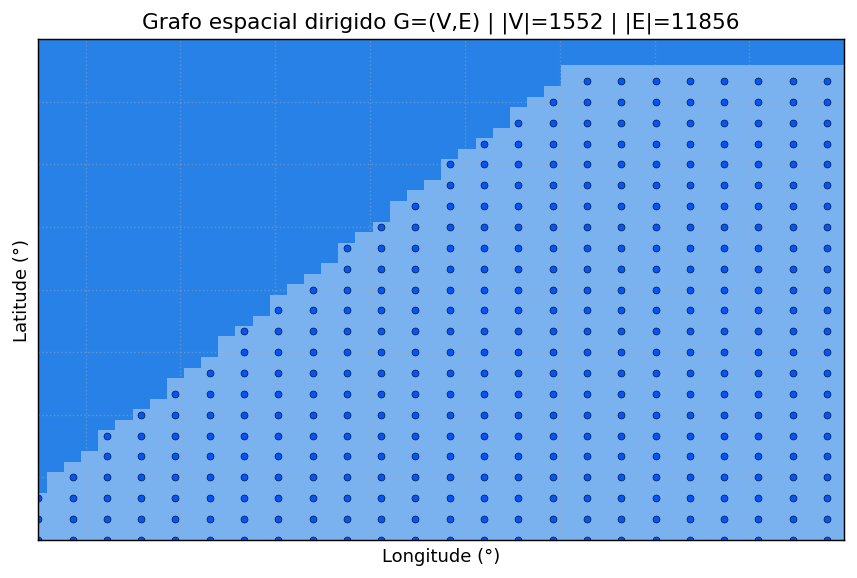

In [5]:
# Fig. 3 - verificação do grafo em grade de teste sintética com a mesma dimensão (49 x 48)
lt = np.linspace(-28, -20, 49); ln = np.linspace(-48.5, -40, 48)
LON, LAT = np.meshgrid(ln, lt)
mag = 0.4 * (np.exp(-(((LON + 43) / 2) ** 2 + ((LAT + 24) / 2) ** 2))
             + 2 * np.exp(-(((LON + 41) / 1) ** 2 + ((LAT + 22) / 1) ** 2)))
terra_t = (LAT > -23 + (LON + 45) * 1.2) | (LAT > -20.5)
Gt = construir_grafo(lt, ln, -0.7 * mag, -0.7 * mag, terra_t)
print(f"Grade de teste: {Gt.number_of_nodes()} nós | {Gt.number_of_edges()} arestas")

pos = {n: (Gt.nodes[n]["pos"][1], Gt.nodes[n]["pos"][0]) for n in Gt.nodes}
sub = Gt.subgraph([n for n in Gt.nodes if n[0] % 2 == 0 and n[1] % 2 == 0])
fig, ax = plt.subplots(figsize=(8, 5), dpi=130)
ax.set_facecolor("#2881e6")
ax.pcolormesh(ln, lt, np.where(terra_t, np.nan, 1), cmap="Blues", shading="nearest", alpha=0.4)
nx.draw_networkx_edges(sub, pos, ax=ax, arrowsize=6, edge_color="#1a1a1a", alpha=0.6, width=0.7, node_size=15)
nx.draw_networkx_nodes(sub, pos, ax=ax, node_size=15, node_color="#0055ff", edgecolors="black", linewidths=0.3)
ax.set(xlim=(-48.5, -40), ylim=(-28, -20), xlabel="Longitude (°)", ylabel="Latitude (°)",
       title=f"Grafo espacial dirigido G=(V,E) | |V|={Gt.number_of_nodes()} | |E|={Gt.number_of_edges()}")
ax.grid(True, ls=":", alpha=0.4)
plt.show()

## 6. Experimento: rota direta × A* de tempo × A* de combustível

In [6]:
# Experimento (Seção IV): rota direta x A* (tempo) x A* (combustível) no estudo de caso costeiro
def executar(instante, s_ll, t_ll, repeticoes=30):
    u, v, terra = matrizes(instante)
    assert np.nanmax(np.hypot(u, v)) <= V_CORR_MAX            # condição de admissibilidade (Seção III-H)
    G = construir_grafo(lats, lons, u, v, terra)
    s, t = agua_mais_proxima(terra, *s_ll), agua_mais_proxima(terra, *t_ll)
    r = dict(dia=str(instante)[:10], origem=s, destino=t, nos_total=G.number_of_nodes())
    rotas = {}
    for crit, rotulo in (("weight", "T"), ("comb", "C")):
        rota, custo, exp_a, _ = busca(G, s, t, crit)
        _, custo_d, exp_d, _ = busca(G, s, t, crit, usar_heuristica=False)
        assert abs(custo - custo_d) < 1e-9                    # A* e Dijkstra: mesmo ótimo
        h_nx = lambda a, b, k=H_FATOR[crit]: haversine(G.nodes[a]["pos"], G.nodes[b]["pos"]) * k
        assert abs(custo_rota(G, nx.astar_path(G, s, t, heuristic=h_nx, weight=crit), crit) - custo) < 1e-9
        t0 = time.perf_counter()
        for _ in range(repeticoes):
            busca(G, s, t, crit)
        r[f"nos_astar_{rotulo}"], r[f"nos_dijkstra_{rotulo}"] = exp_a, exp_d
        r[f"ms_{rotulo}"] = (time.perf_counter() - t0) / repeticoes * 1000
        rotas[rotulo] = rota
    dcel, inval = rota_direta(G, s, t)
    rotas["D"] = dcel
    r["arestas_invalidas_direta"] = len(inval)
    for k, rota in rotas.items():                              # cada rota avaliada nos DOIS critérios
        r[f"tempo_{k}"] = custo_rota(G, rota, "weight")
        r[f"comb_{k}"] = custo_rota(G, rota, "comb")
        r[f"km_{k}"] = comprimento_km(G, rota)
        r[f"celulas_{k}"] = len(rota)
    r["rotas"] = rotas
    r["ganho_tempo_pct"] = 100 * (r["tempo_D"] - r["tempo_T"]) / r["tempo_D"]
    r["ganho_comb_pct"] = 100 * (r["comb_D"] - r["comb_C"]) / r["comb_D"]
    r["ganho_comb_vs_T_pct"] = 100 * (r["comb_T"] - r["comb_C"]) / r["comb_T"]
    r["reducao_nos_T_pct"] = 100 * (r["nos_dijkstra_T"] - r["nos_astar_T"]) / r["nos_dijkstra_T"]
    r["reducao_nos_C_pct"] = 100 * (r["nos_dijkstra_C"] - r["nos_astar_C"]) / r["nos_dijkstra_C"]
    return r

# Estudo de caso: navegação costeira (extremos sudoeste e nordeste do recorte)
CENARIO = dict(s_ll=(-26.0, -47.0), t_ll=(-22.9167, -43.0833))
res = executar(instantes[0], **CENARIO)

tab = pd.DataFrame({
    "Tempo (h)":          [res["tempo_D"], res["tempo_T"], res["tempo_C"]],
    "Combustível (u.r.)": [res["comb_D"],  res["comb_T"],  res["comb_C"]],
    "Comprimento (km)":   [res["km_D"],    res["km_T"],    res["km_C"]],
    "Células":            [res["celulas_D"], res["celulas_T"], res["celulas_C"]],
}, index=["Rota direta", "A* de tempo", "A* de combustível"])
print(f"Dia {res['dia']} | nós navegáveis: {res['nos_total']}\n")
print(tab.round(2).to_string())
ind = ["ganho_tempo_pct", "ganho_comb_pct", "ganho_comb_vs_T_pct", "nos_astar_T", "nos_dijkstra_T",
       "nos_astar_C", "nos_dijkstra_C", "reducao_nos_T_pct", "reducao_nos_C_pct", "ms_T", "ms_C",
       "arestas_invalidas_direta"]
print()
print(pd.Series({k: res[k] for k in ind}).astype(float).round(2).to_string())

Dia 2026-08-18 | nós navegáveis: 1494

                   Tempo (h)  Combustível (u.r.)  Comprimento (km)  Células
Rota direta            30.75               33.01            547.93       48
A* de tempo            30.43               31.97            548.86       48
A* de combustível      30.43               31.97            548.86       48

ganho_tempo_pct                1.03
ganho_comb_pct                 3.17
ganho_comb_vs_T_pct            0.00
nos_astar_T                 1264.00
nos_dijkstra_T              1494.00
nos_astar_C                 1452.00
nos_dijkstra_C              1494.00
reducao_nos_T_pct             15.39
reducao_nos_C_pct              2.81
ms_T                          25.49
ms_C                          20.99
arestas_invalidas_direta       0.00


## 7. Mapa das rotas

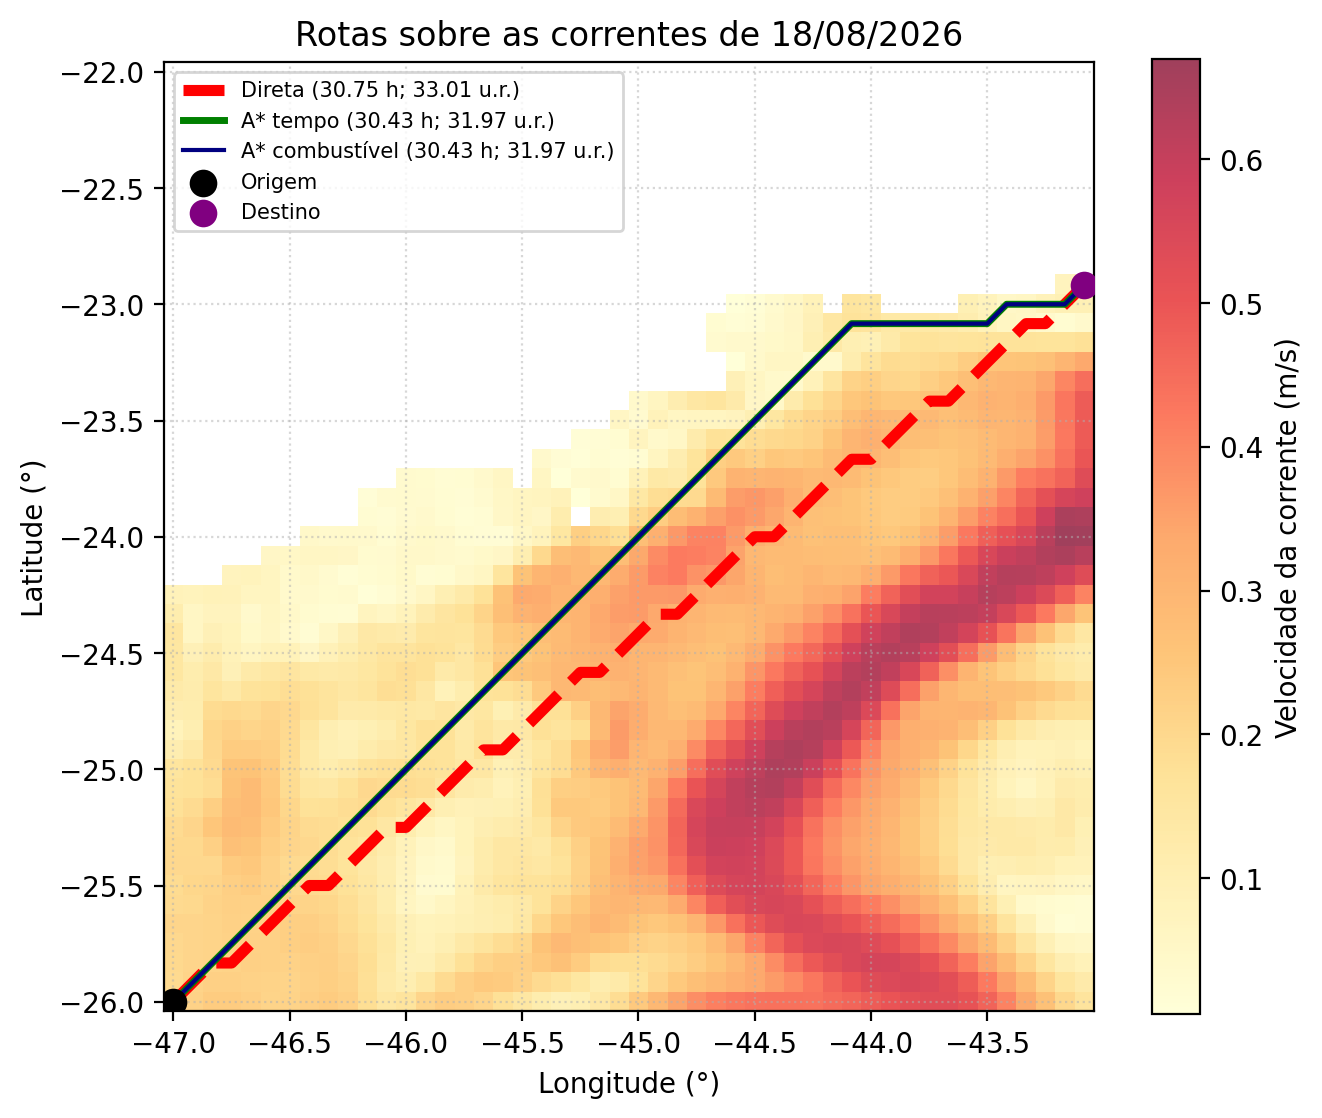

In [7]:
# Mapa das rotas (Fig. 4)
u, v, terra = matrizes(instantes[0])
mag = np.where(terra, np.nan, np.hypot(u, v))
dl, dn = (lats[1] - lats[0]) / 2, (lons[1] - lons[0]) / 2
fig, ax = plt.subplots(figsize=(7.5, 6.2), dpi=200)
im = ax.imshow(mag, origin="lower", cmap="YlOrRd", alpha=0.75,
               extent=[lons[0] - dn, lons[-1] + dn, lats[0] - dl, lats[-1] + dl])
fig.colorbar(im, ax=ax, label="Velocidade da corrente (m/s)")
xy = lambda rota: ([lons[c] for _, c in rota], [lats[q] for q, _ in rota])
ax.plot(*xy(res["rotas"]["D"]), "r--", lw=4, label=f"Direta ({res['tempo_D']:.2f} h; {res['comb_D']:.2f} u.r.)")
ax.plot(*xy(res["rotas"]["T"]), "g-", lw=2.5, label=f"A* tempo ({res['tempo_T']:.2f} h; {res['comb_T']:.2f} u.r.)")
ax.plot(*xy(res["rotas"]["C"]), color="navy", lw=1.5, label=f"A* combustível ({res['tempo_C']:.2f} h; {res['comb_C']:.2f} u.r.)")
s, t = res["origem"], res["destino"]
ax.scatter(lons[s[1]], lats[s[0]], c="black", s=80, zorder=5, label="Origem")
ax.scatter(lons[t[1]], lats[t[0]], c="purple", s=80, zorder=5, label="Destino")
ax.set(title="Rotas sobre as correntes de 18/08/2026", xlabel="Longitude (°)", ylabel="Latitude (°)")
ax.grid(True, ls=":", alpha=0.5); ax.legend(loc="upper left", fontsize=7.5)
fig.savefig("mapa_rotas.png", bbox_inches="tight"); plt.show()

## 8. Repetição nos três dias do recorte

In [8]:
# Complemento: repetição do experimento nos três dias do recorte
linhas = []
for t in instantes:
    r = executar(t, **CENARIO, repeticoes=3)
    linhas.append({k: r[k] for k in ["dia", "tempo_D", "tempo_T", "ganho_tempo_pct", "comb_D", "comb_C",
                                     "ganho_comb_pct", "comb_T", "nos_astar_T", "nos_astar_C", "nos_dijkstra_C"]})
print(pd.DataFrame(linhas).round(3).to_string(index=False))

       dia  tempo_D  tempo_T  ganho_tempo_pct  comb_D  comb_C  ganho_comb_pct  comb_T  nos_astar_T  nos_astar_C  nos_dijkstra_C
2026-08-18   30.751   30.435            1.030  33.012  31.966           3.170  31.966         1264         1452            1494
2026-08-19   29.629   29.241            1.310  29.651  28.390           4.253  28.390         1195         1291            1494
2026-08-20   29.381   28.943            1.488  28.908  27.506           4.849  27.506         1156         1179            1494


## 9. Sensibilidade à intensidade das correntes

In [9]:
# Sensibilidade (artificial): correntes multiplicadas por um fator, para ver quando o critério muda a rota.
# Com correntes ampliadas as heurísticas deixam de ser admissíveis; por isso usa-se Dijkstra (h = 0).
u0, v0, terra0 = matrizes(instantes[0])
s_, t_ = res["origem"], res["destino"]
sens = []
for f in (1, 3, 6):
    Gf = construir_grafo(lats, lons, f * u0, f * v0, terra0)
    rT = busca(Gf, s_, t_, "weight", usar_heuristica=False)[0]
    rC = busca(Gf, s_, t_, "comb", usar_heuristica=False)[0]
    rD = rota_direta(Gf, s_, t_)[0]
    sens.append(dict(fator=f, corrente_max_ms=round(f * float(np.nanmax(np.hypot(u0, v0))), 2),
                     mesma_rota=rT == rC,
                     comb_direta=custo_rota(Gf, rD, "comb"), comb_Atempo=custo_rota(Gf, rT, "comb"),
                     comb_Acomb=custo_rota(Gf, rC, "comb"),
                     tempo_direta=custo_rota(Gf, rD, "weight"), tempo_Atempo=custo_rota(Gf, rT, "weight"),
                     tempo_Acomb=custo_rota(Gf, rC, "weight")))
sens = pd.DataFrame(sens)
sens["ganho_comb_vs_direta_pct"] = 100 * (sens.comb_direta - sens.comb_Acomb) / sens.comb_direta
sens["ganho_comb_vs_Atempo_pct"] = 100 * (sens.comb_Atempo - sens.comb_Acomb) / sens.comb_Atempo
print(sens.round(2).T.to_string(header=False))

fator                         1      3      6
corrente_max_ms            0.67   2.01   4.02
mesma_rota                 True  False  False
comb_direta               33.01  40.77  55.05
comb_Atempo               31.97  36.58   37.2
comb_Acomb                31.97  33.98  35.99
tempo_direta              30.75  33.39  38.74
tempo_Atempo              30.43  32.19  33.56
tempo_Acomb               30.43  32.81  33.89
ganho_comb_vs_direta_pct   3.17  16.64  34.61
ganho_comb_vs_Atempo_pct    0.0   7.09   3.25
